In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

print("WeatherWise India - Project Started!")

WeatherWise India - Project Started!


In [ ]:
cities = {
    "Mumbai": (19.0760, 72.8777),
    "Delhi": (28.6139, 77.2090),
    "Bengaluru": (12.9716, 77.5946),
    "Chennai": (13.0827, 80.2708),
    "Kolkata": (22.5726, 88.3639)
}

url = "https://archive-api.open-meteo.com/v1/archive"

all_data = []

for city, (lat, lon) in cities.items():

    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": "2021-01-01",
        "end_date": "2025-12-31",
        "hourly": [
            "temperature_2m",
            "relative_humidity_2m",
            "pressure_msl",
            "rain",
            "cloud_cover",
            "wind_speed_10m"
        ],
        "timezone": "Asia/Kolkata",
        "models": "era5"
    }

    response = requests.get(url, params=params, timeout=120)
    response.raise_for_status()

    data = response.json()

    if data.get("error"):
        raise ValueError(data.get("reason"))

    hourly_df = pd.DataFrame(data["hourly"])

    hourly_df["time"] = pd.to_datetime(hourly_df["time"])
    hourly_df["Date"] = hourly_df["time"].dt.date

    daily_df = hourly_df.groupby("Date").agg(
        Temperature_Mean=("temperature_2m", "mean"),
        Temperature_Max=("temperature_2m", "max"),
        Temperature_Min=("temperature_2m", "min"),
        Humidity_Mean=("relative_humidity_2m", "mean"),
        Pressure_Mean=("pressure_msl", "mean"),
        Wind_Speed_Max=("wind_speed_10m", "max"),
        Cloud_Cover_Mean=("cloud_cover", "mean"),
        Rainfall_mm=("rain", lambda x: x.sum(min_count=1))
    ).reset_index()

    daily_df.insert(0, "City", city)

    all_data.append(daily_df)

    print(city, "completed:", len(daily_df), "days")

df = pd.concat(all_data, ignore_index=True)

df["Date"] = pd.to_datetime(df["Date"])

print("\nDataset collected successfully!")
print("Dataset shape:", df.shape)

display(df.head())
# Save dataset as CSV
df.to_csv("WeatherWise_India_2021_2025.csv", index=False)

print("CSV file saved successfully!")

Mumbai completed: 1826 days
Delhi completed: 1826 days
Bengaluru completed: 1826 days
Chennai completed: 1826 days
Kolkata completed: 1826 days

Dataset collected successfully!
Dataset shape: (9130, 10)


,City,Date,Temperature_Mean,Temperature_Max,Temperature_Min,Humidity_Mean,Pressure_Mean,Wind_Speed_Max,Cloud_Cover_Mean,Rainfall_mm
0,Mumbai,2021-01-01,25.691667,30.8,21.6,73.041667,1011.450000,15.8,24.291667,0.0
1,Mumbai,2021-01-02,25.541667,29.6,23.4,76.083333,1012.208333,13.6,50.708333,0.2
2,Mumbai,2021-01-03,24.779167,29.7,21.7,72.208333,1010.675000,15.9,8.750000,0.0
3,Mumbai,2021-01-04,24.662500,28.3,21.9,70.000000,1010.604167,15.9,39.916667,0.2
4,Mumbai,2021-01-05,24.845833,28.9,22.0,69.916667,1011.737500,18.1,28.833333,0.0


CSV file saved successfully!


In [ ]:

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Information about columns
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Count records city-wise
print("\nRecords per City:")
print(df["City"].value_counts())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Download CSV file
from google.colab import files
files.download("WeatherWise_India_2021_2025.csv")


Dataset Shape: (9130, 10)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9130 entries, 0 to 9129
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   City              9130 non-null   object        
 1   Date              9130 non-null   datetime64[ns]
 2   Temperature_Mean  9130 non-null   float64       
 3   Temperature_Max   9130 non-null   float64       
 4   Temperature_Min   9130 non-null   float64       
 5   Humidity_Mean     9130 non-null   float64       
 6   Pressure_Mean     9130 non-null   float64       
 7   Wind_Speed_Max    9130 non-null   float64       
 8   Cloud_Cover_Mean  9130 non-null   float64       
 9   Rainfall_mm       9130 non-null   float64       
dtypes: datetime64[ns](1), float64(8), object(1)
memory usage: 713.4+ KB

Missing Values:
City                0
Date                0
Temperature_Mean    0
Temperature_Max     0
Temperature_Min    

,Date,Temperature_Mean,Temperature_Max,Temperature_Min,Humidity_Mean,Pressure_Mean,Wind_Speed_Max,Cloud_Cover_Mean,Rainfall_mm
count,9130,9130.000000,9130.000000,9130.000000,9130.000000,9130.000000,9130.000000,9130.000000,9130.000000
mean,2023-07-02 12:00:00,26.272490,30.567645,22.919014,74.289576,1009.166464,15.536791,52.307215,3.825794
min,2021-01-01 00:00:00,7.970833,12.600000,3.700000,21.000000,987.254167,4.700000,0.000000,0.000000
25%,2022-04-02 00:00:00,23.804167,28.100000,20.200000,69.250000,1005.808333,11.700000,18.177083,0.000000
50%,2023-07-02 12:00:00,27.043750,30.800000,24.300000,76.583333,1009.693750,15.000000,51.729167,0.100000
75%,2024-10-01 00:00:00,29.404167,33.000000,26.900000,82.708333,1012.900000,18.600000,90.333333,3.200000
max,2025-12-31 00:00:00,40.062500,46.500000,35.500000,99.000000,1024.841667,54.200000,100.000000,208.400000
std,NaN,4.398732,4.125545,5.048010,12.320354,4.986135,5.197690,36.045171,9.777443


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Make a copy of original dataset
df_clean = df.copy()

# Check missing values
print("Missing values before cleaning:")
print(df_clean.isnull().sum())

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Fill missing numerical values using city-wise median
numerical_cols = df_clean.select_dtypes(include=np.number).columns

df_clean[numerical_cols] = df_clean.groupby("City")[numerical_cols].transform(
    lambda x: x.fillna(x.median())
)

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nFinal dataset shape:", df_clean.shape)

display(df_clean.head())

Missing values before cleaning:
City                0
Date                0
Temperature_Mean    0
Temperature_Max     0
Temperature_Min     0
Humidity_Mean       0
Pressure_Mean       0
Wind_Speed_Max      0
Cloud_Cover_Mean    0
Rainfall_mm         0
dtype: int64

Missing values after cleaning:
City                0
Date                0
Temperature_Mean    0
Temperature_Max     0
Temperature_Min     0
Humidity_Mean       0
Pressure_Mean       0
Wind_Speed_Max      0
Cloud_Cover_Mean    0
Rainfall_mm         0
dtype: int64

Final dataset shape: (9130, 10)


,City,Date,Temperature_Mean,Temperature_Max,Temperature_Min,Humidity_Mean,Pressure_Mean,Wind_Speed_Max,Cloud_Cover_Mean,Rainfall_mm
0,Mumbai,2021-01-01,25.691667,30.8,21.6,73.041667,1011.450000,15.8,24.291667,0.0
1,Mumbai,2021-01-02,25.541667,29.6,23.4,76.083333,1012.208333,13.6,50.708333,0.2
2,Mumbai,2021-01-03,24.779167,29.7,21.7,72.208333,1010.675000,15.9,8.750000,0.0
3,Mumbai,2021-01-04,24.662500,28.3,21.9,70.000000,1010.604167,15.9,39.916667,0.2
4,Mumbai,2021-01-05,24.845833,28.9,22.0,69.916667,1011.737500,18.1,28.833333,0.0


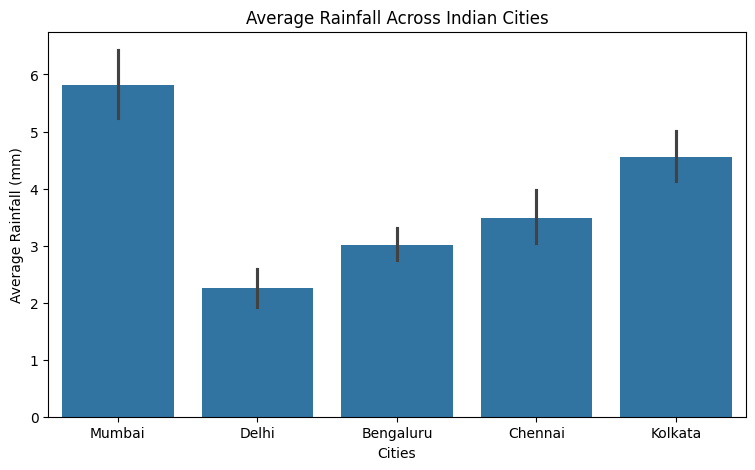

In [ ]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=df_clean,
    x="City",
    y="Rainfall_mm",
    estimator="mean"
)

plt.title("Average Rainfall Across Indian Cities")
plt.xlabel("Cities")
plt.ylabel("Average Rainfall (mm)")
plt.show()

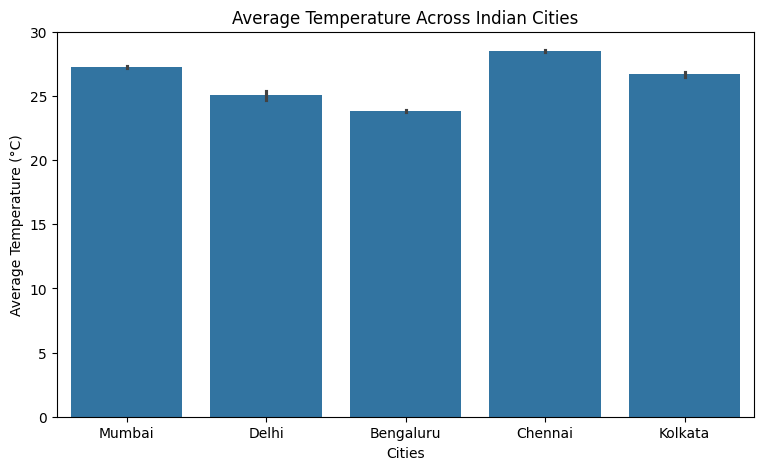

In [ ]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=df_clean,
    x="City",
    y="Temperature_Mean",
    estimator="mean"
)

plt.title("Average Temperature Across Indian Cities")
plt.xlabel("Cities")
plt.ylabel("Average Temperature (°C)")
plt.show()

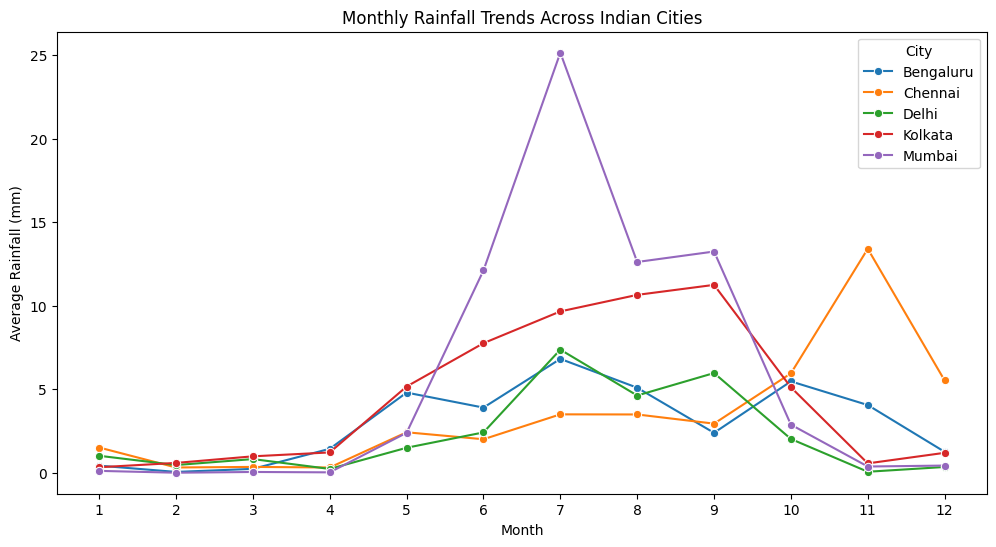

In [ ]:
df_clean["Month"] = df_clean["Date"].dt.month

monthly_rainfall = df_clean.groupby(
    ["Month", "City"]
)["Rainfall_mm"].mean().reset_index()

plt.figure(figsize=(12,6))

sns.lineplot(
    data=monthly_rainfall,
    x="Month",
    y="Rainfall_mm",
    hue="City",
    marker="o"
)

plt.title("Monthly Rainfall Trends Across Indian Cities")
plt.xlabel("Month")
plt.ylabel("Average Rainfall (mm)")
plt.xticks(range(1,13))
plt.legend(title="City")
plt.show()

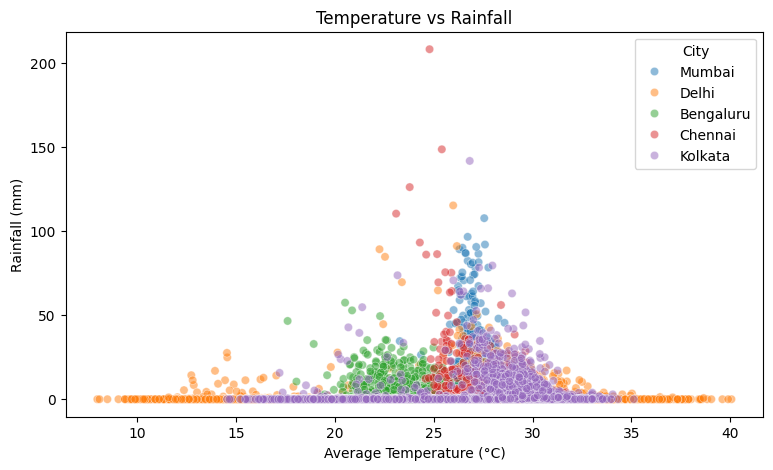

In [ ]:
plt.figure(figsize=(9,5))

sns.scatterplot(
    data=df_clean,
    x="Temperature_Mean",
    y="Rainfall_mm",
    hue="City",
    alpha=0.5
)

plt.title("Temperature vs Rainfall")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("Rainfall (mm)")
plt.show()

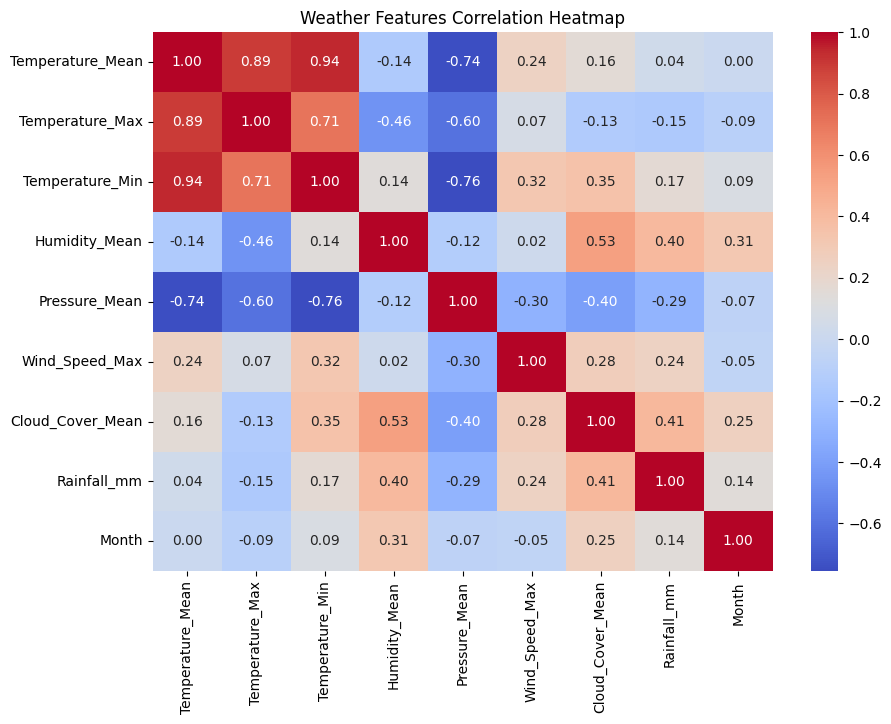

In [ ]:
plt.figure(figsize=(10,7))

correlation = df_clean.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Weather Features Correlation Heatmap")
plt.show()

In [ ]:
# Sort data city-wise and date-wise
df_clean = df_clean.sort_values(
    ["City", "Date"]
).reset_index(drop=True)

# Create next-day rainfall column
df_clean["Next_Day_Rainfall"] = (
    df_clean.groupby("City")["Rainfall_mm"].shift(-1)
)

# Create binary target
df_clean["Rain_Tomorrow"] = (
    df_clean["Next_Day_Rainfall"] >= 0.1
).astype(int)

# Remove last day of each city (no next-day data)
df_clean = df_clean.dropna(
    subset=["Next_Day_Rainfall"]
).copy()

print("Target created successfully!")

print("\nTarget distribution:")
print(df_clean["Rain_Tomorrow"].value_counts())

print("\nTarget percentages:")
print(df_clean["Rain_Tomorrow"].value_counts(normalize=True) * 100)

display(df_clean[[
    "City",
    "Date",
    "Rainfall_mm",
    "Next_Day_Rainfall",
    "Rain_Tomorrow"
]].head(10))

Target created successfully!

Target distribution:
Rain_Tomorrow
1    4637
0    4488
Name: count, dtype: int64

Target percentages:
Rain_Tomorrow
1    50.816438
0    49.183562
Name: proportion, dtype: float64


,City,Date,Rainfall_mm,Next_Day_Rainfall,Rain_Tomorrow
0,Bengaluru,2021-01-01,0.0,0.5,1
1,Bengaluru,2021-01-02,0.5,0.2,1
2,Bengaluru,2021-01-03,0.2,0.0,0
3,Bengaluru,2021-01-04,0.0,0.6,1
4,Bengaluru,2021-01-05,0.6,9.0,1
5,Bengaluru,2021-01-06,9.0,27.4,1
6,Bengaluru,2021-01-07,27.4,1.4,1
7,Bengaluru,2021-01-08,1.4,0.0,0
8,Bengaluru,2021-01-09,0.0,0.0,0
9,Bengaluru,2021-01-10,0.0,0.8,1


In [ ]:
from sklearn.model_selection import train_test_split

# Create month feature
df_clean["Month"] = df_clean["Date"].dt.month

# Select input features
features = [
    "City",
    "Month",
    "Temperature_Mean",
    "Temperature_Max",
    "Temperature_Min",
    "Humidity_Mean",
    "Pressure_Mean",
    "Wind_Speed_Max",
    "Cloud_Cover_Mean",
    "Rainfall_mm"
]

X = df_clean[features]
y = df_clean["Rain_Tomorrow"]

# Chronological split
train_data = df_clean[df_clean["Date"] < "2025-01-01"]
test_data = df_clean[df_clean["Date"] >= "2025-01-01"]

X_train = train_data[features]
X_test = test_data[features]

y_train = train_data["Rain_Tomorrow"]
y_test = test_data["Rain_Tomorrow"]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining period:",
      train_data["Date"].min(),
      "to",
      train_data["Date"].max())

print("\nTesting period:",
      test_data["Date"].min(),
      "to",
      test_data["Date"].max())

Training records: 7305
Testing records: 1820

Training period: 2021-01-01 00:00:00 to 2024-12-31 00:00:00

Testing period: 2025-01-01 00:00:00 to 2025-12-30 00:00:00


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Identify numerical and categorical columns
numeric_features = [
    "Month",
    "Temperature_Mean",
    "Temperature_Max",
    "Temperature_Min",
    "Humidity_Mean",
    "Pressure_Mean",
    "Wind_Speed_Max",
    "Cloud_Cover_Mean",
    "Rainfall_mm"
]

categorical_features = ["City"]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Define models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}

# Train all models
for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

    print("\n", name)
    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Rain", "Rain"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")
display(results_df.round(4))


 Logistic Regression
              precision    recall  f1-score   support

     No Rain       0.83      0.86      0.85       874
        Rain       0.87      0.83      0.85       946

    accuracy                           0.85      1820
   macro avg       0.85      0.85      0.85      1820
weighted avg       0.85      0.85      0.85      1820

Confusion Matrix:
[[756 118]
 [157 789]]

 Decision Tree
              precision    recall  f1-score   support

     No Rain       0.84      0.86      0.85       874
        Rain       0.87      0.85      0.86       946

    accuracy                           0.86      1820
   macro avg       0.86      0.86      0.86      1820
weighted avg       0.86      0.86      0.86      1820

Confusion Matrix:
[[756 118]
 [145 801]]

 Random Forest
              precision    recall  f1-score   support

     No Rain       0.85      0.89      0.87       874
        Rain       0.90      0.86      0.88       946

    accuracy                           0.87   

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8489,0.8699,0.8340,0.8516
1,Decision Tree,0.8555,0.8716,0.8467,0.8590
2,Random Forest,0.8747,0.8962,0.8584,0.8769


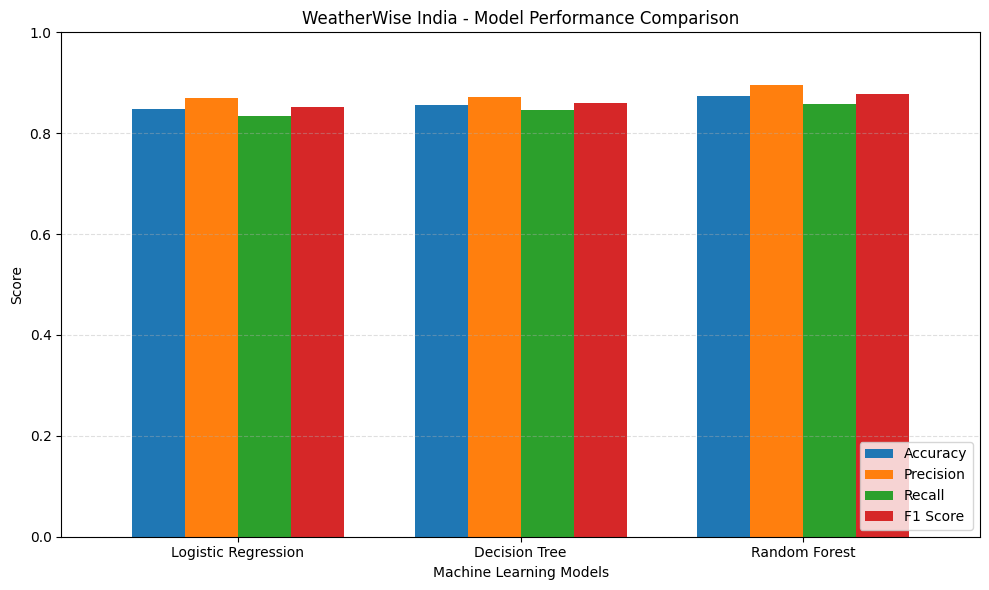

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    width=0.75
)

plt.title("WeatherWise India - Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Feature Importance Ranking:


,Feature,Importance
8,num__Rainfall_mm,0.265389
7,num__Cloud_Cover_Mean,0.169849
4,num__Humidity_Mean,0.119970
5,num__Pressure_Mean,0.103910
0,num__Month,0.080173
3,num__Temperature_Min,0.065487
1,num__Temperature_Mean,0.063681
6,num__Wind_Speed_Max,0.052469
2,num__Temperature_Max,0.051859
9,cat__City_Bengaluru,0.006214


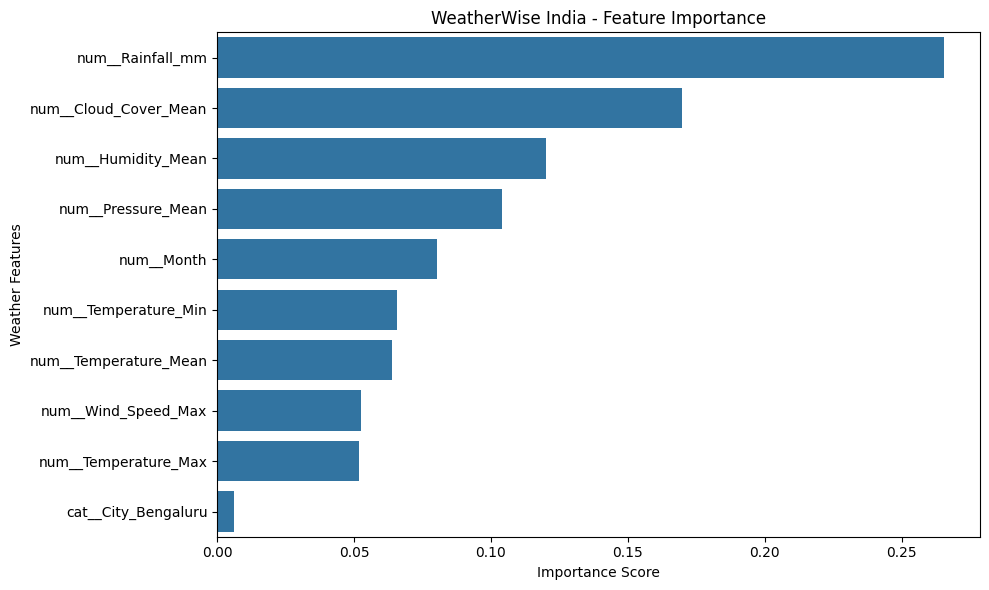

In [ ]:
# Feature Importance Analysis

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get the trained Random Forest pipeline
rf_model = trained_models["Random Forest"]

# Extract the preprocessing and model steps
preprocessor = rf_model.named_steps["preprocessing"]
classifier = rf_model.named_steps["model"]

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get feature importance scores
importance = classifier.feature_importances_

# Create feature importance DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

print("Feature Importance Ranking:")
display(importance_df)

# Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("WeatherWise India - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Weather Features")
plt.tight_layout()
plt.show()

In [ ]:
# WeatherWise India - Rain Prediction Demonstration

# Select one record from the testing dataset
sample_weather = X_test.iloc[[0]]

# Predict using Random Forest
prediction = rf_model.predict(sample_weather)[0]

# Get actual result
actual = y_test.iloc[0]

# Display input weather information
print("WEATHER INPUT:")
display(sample_weather)

# Display prediction
print("\nWEATHERWISE INDIA PREDICTION:")

if prediction == 1:
    print("Prediction: Rain Tomorrow")
else:
    print("Prediction: No Rain Tomorrow")

# Compare with actual result
print("\nACTUAL RESULT:")

if actual == 1:
    print("Actual: Rain Tomorrow")
else:
    print("Actual: No Rain Tomorrow")

print("\nPrediction Correct:", prediction == actual)

WEATHER INPUT:


,City,Month,Temperature_Mean,Temperature_Max,Temperature_Min,Humidity_Mean,Pressure_Mean,Wind_Speed_Max,Cloud_Cover_Mean,Rainfall_mm
1461,Bengaluru,1,21.2125,26.6,16.8,72.125,1015.641667,17.1,30.333333,0.0



WEATHERWISE INDIA PREDICTION:
Prediction: No Rain Tomorrow

ACTUAL RESULT:
Actual: No Rain Tomorrow

Prediction Correct: True


In [ ]:
# Save the Best Performing Model

import joblib

# Save the complete Random Forest pipeline
joblib.dump(
    rf_model,
    "WeatherWise_RandomForest_Model.pkl"
)

print("Random Forest Model Saved Successfully!")

Random Forest Model Saved Successfully!


In [ ]:
# Load the saved model

loaded_model = joblib.load(
    "WeatherWise_RandomForest_Model.pkl"
)

print("Model Loaded Successfully!")

# Test the loaded model
test_prediction = loaded_model.predict(X_test.iloc[[0]])

print("Loaded Model Prediction:", test_prediction[0])

Model Loaded Successfully!
Loaded Model Prediction: 0


In [ ]:
from google.colab import files

files.download("WeatherWise_RandomForest_Model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#to check whats inside pkl file
import joblib

# Load your model
model = joblib.load("WeatherWise_RandomForest_Model.pkl")

# Display model details
print(model)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Month', 'Temperature_Mean',
                                                   'Temperature_Max',
                                                   'Temperature_Min',
                                                   'Humidity_Mean',
                                                   'Pressure_Mean',
                                                   'Wind_Speed_Max',
                                                   'Cloud_Cover_Mean',
                                                   'Rainfall_mm']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['City'])])),
                ('model',
                 RandomForestClassifier(max_depth=15, n_jobs=-1,
                         

In [ ]:
# Display Random Forest parameters
print(model.named_steps["model"].get_params())

{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 15, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


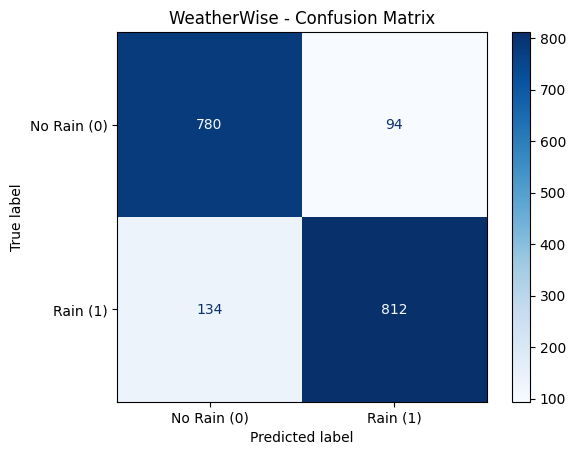

Prediction: 0


In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix graph
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Rain (0)", "Rain (1)"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("WeatherWise - Confusion Matrix")
plt.show()

prediction = model.predict(X_test.iloc[[0]])

print("Prediction:", prediction[0])

In [ ]:
import joblib
import os

# Save your existing trained model
joblib.dump(
    model,
    "WeatherWise_RandomForest_Model_fixed.pkl",
    compress=3
)

print("Model saved successfully!")
print("File size:", os.path.getsize(
    "WeatherWise_RandomForest_Model_fixed.pkl"
), "bytes")

Model saved successfully!
File size: 2478339 bytes


In [ ]:
loaded_model = joblib.load(
    "WeatherWise_RandomForest_Model_fixed.pkl"
)

prediction = loaded_model.predict(X_test.iloc[[0]])

print("Model loaded successfully!")
print("Prediction:", prediction[0])

Model loaded successfully!
Prediction: 0


In [ ]:
from google.colab import files

files.download("WeatherWise_RandomForest_Model_fixed.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import joblib
import zipfile
import os

# Save your existing trained model
model_path = "WeatherWise_Model.pkl"

joblib.dump(model, model_path, compress=3)

# Verify model can be loaded in Colab
test_model = joblib.load(model_path)

print("Model verification successful!")
print("Model size:", os.path.getsize(model_path), "bytes")
print("Prediction:", test_model.predict(X_test.iloc[[0]])[0])

# Create ZIP file
with zipfile.ZipFile("WeatherWise_Model.zip", "w",
                     zipfile.ZIP_DEFLATED) as zip_file:
    zip_file.write(model_path)

print("ZIP created successfully!")
print("ZIP size:", os.path.getsize("WeatherWise_Model.zip"), "bytes")


Model verification successful!
Model size: 2476523 bytes
Prediction: 0
ZIP created successfully!
ZIP size: 2439492 bytes


In [ ]:
from google.colab import files
files.download("WeatherWise_Model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import joblib
import os
import zipfile

# Save the trained model
joblib.dump(model, "WeatherWise_RandomForest_Model_fixed.pkl", compress=3)

# Verify that the file is not empty
print("File size:", os.path.getsize("WeatherWise_RandomForest_Model_fixed.pkl"), "bytes")

# Test loading it
test_model = joblib.load("WeatherWise_RandomForest_Model_fixed.pkl")
print("Model loaded successfully!")
print("Prediction:", test_model.predict(X_test.iloc[[0]])[0])

# Create a ZIP file
with zipfile.ZipFile("WeatherWise_RandomForest_Model_fixed.zip", "w", zipfile.ZIP_DEFLATED) as zip_file:
    zip_file.write("WeatherWise_RandomForest_Model_fixed.pkl")

File size: 2476523 bytes
Model loaded successfully!
Prediction: 0


In [ ]:
from google.colab import files
files.download("WeatherWise_RandomForest_Model_fixed.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import joblib
import os

# Check that the trained model exists
print("Model variable:", type(model))

# Save the trained model
joblib.dump(
    model,
    "WeatherWise_RandomForest_Model_fixed.pkl",
    compress=3
)

# Verify file size
size = os.path.getsize("WeatherWise_RandomForest_Model_fixed.pkl")
print("Saved model size:", size, "bytes")

# Test loading
loaded_model = joblib.load("WeatherWise_RandomForest_Model_fixed.pkl")
print("Model loaded successfully!")

# Test prediction
print("Prediction:", loaded_model.predict(X_test.iloc[[0]]))


Model variable: <class 'sklearn.pipeline.Pipeline'>
Saved model size: 2476523 bytes
Model loaded successfully!
Prediction: [0]


In [ ]:

from google.colab import files

files.download("WeatherWise_RandomForest_Model_fixed.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import os
import joblib

print("Model variable exists:", "model" in globals())

if "model" in globals():
    print("Model type:", type(model))

    joblib.dump(model, "WeatherWise_RandomForest_Model_fixed.pkl", compress=3)

    print("Saved file size:",
          os.path.getsize("WeatherWise_RandomForest_Model_fixed.pkl"),
          "bytes")

    loaded_model = joblib.load("WeatherWise_RandomForest_Model_fixed.pkl")
    print("Model loading successful!")
else:
    print("Model not found. Run your Random Forest training cell first.")


Model variable exists: True
Model type: <class 'sklearn.pipeline.Pipeline'>
Saved file size: 2476523 bytes
Model loading successful!


In [ ]:
from google.colab import files

files.download("WeatherWise_RandomForest_Model_fixed.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("WeatherWise_RandomForest_Model_fixed.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>